# 07 - Model Comparison

Goal:
Compare logistic regression, a tree-based model, and a gradient-boosted model
on exactly the same setup, calibrate their probabilities, and recommend one.

Shared setup (same as `04_logistic_baseline` and `05_gradient_boosting`):
- Target: `pay_casheqv` (1 = could not cover a $400 emergency with cash or equivalent)
- Split: `outputs/tables/train_test_split.csv`
- Survey weight `weight` used in training and evaluation
- The same 12 predictors

This notebook:
- trains and tunes a random forest (the tree-based model) on the shared setup
- re-fits the logistic regression from `04` and the tuned XGBoost from `05`, and
  checks that they reproduce their saved results
- calibrates all three with `CalibratedClassifierCV`
- compares all three in one table and on shared ROC, precision-recall, and
  calibration charts

Note: the decision tree in `notebooks_TreeBasedModel-Thrivent1B.ipynb` predicts a
different target (`B2`) with its own split and features, so it is not part of this
comparison. It is relevant to the secondary-target stretch goal.

In [1]:
import os
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
from xgboost import XGBClassifier

SEED = 42

## Shared Setup

In [2]:
df = pd.read_csv(
    os.path.join("..", "data", "raw", "SHED 2025 CSV Raw.csv"),
    low_memory=False
)

target = df["pay_casheqv"].map({"Yes": 0, "No": 1})  # 1 = fragile
sample_weight = df["weight"]

categorical_features = [
    "B2", "EF1", "ppinc7", "FD3", "E2B",
    "A6", "ppeduc5", "GH1", "I9", "ppemploy"
]
numeric_features = ["ppage", "pphhsize"]
features = categorical_features + numeric_features

split = pd.read_csv(
    "../outputs/tables/train_test_split.csv"
).set_index("index")["split"]

assert split.index.equals(df.index)

train_idx = split.index[split == "train"]
test_idx = split.index[split == "test"]

X_train = df.loc[train_idx, features]
X_test = df.loc[test_idx, features]
y_train = target.loc[train_idx]
y_test = target.loc[test_idx]
w_train = sample_weight.loc[train_idx]
w_test = sample_weight.loc[test_idx]

print(X_train.shape, X_test.shape)

(10347, 12) (2587, 12)


## Preprocessing

Same preprocessing as `04_logistic_baseline`, fit on the training set only.
Logistic regression and the random forest use the one-hot matrix; XGBoost reads
the categories directly, as in `05_gradient_boosting`.

In [3]:
preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="NOT_ASKED")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

X_xgb = df[features].copy()
for col in categorical_features:
    X_xgb[col] = X_xgb[col].fillna("NOT_ASKED").astype("category")

X_train_xgb = X_xgb.loc[train_idx]
X_test_xgb = X_xgb.loc[test_idx]

print(X_train_prepared.shape)

(10347, 40)


In [4]:
def evaluate(name, y_true, prob, weights, threshold=0.5):
    pred = (prob >= threshold).astype(int)

    return {
        "Model": name,
        "ROC_AUC": roc_auc_score(y_true, prob, sample_weight=weights),
        "PR_AUC": average_precision_score(y_true, prob, sample_weight=weights),
        "Brier": brier_score_loss(y_true, prob, sample_weight=weights),
        "Accuracy": accuracy_score(y_true, pred, sample_weight=weights),
        "Precision": precision_score(y_true, pred, sample_weight=weights, zero_division=0),
        "Recall": recall_score(y_true, pred, sample_weight=weights),
        "F1": f1_score(y_true, pred, sample_weight=weights)
    }

## Tree-Based Model: Random Forest

Tuned with 5-fold weighted cross-validation on the training set only, ranked by
Brier score, the same procedure `05_gradient_boosting` used for XGBoost. The test
set is not used to choose settings.

In [5]:
param_grid = {
    "max_depth": [6, 10, None],
    "min_samples_leaf": [5, 20, 50],
    "max_features": ["sqrt", 0.5]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y_train_arr = y_train.to_numpy()
w_train_arr = w_train.to_numpy()

cv_results = []

for depth, leaf, max_feat in product(*param_grid.values()):
    fold_auc, fold_brier = [], []

    for fit_idx, val_idx in cv.split(X_train_prepared, y_train_arr):
        model = RandomForestClassifier(
            n_estimators=300,
            max_depth=depth,
            min_samples_leaf=leaf,
            max_features=max_feat,
            random_state=SEED,
            n_jobs=-1
        )
        model.fit(
            X_train_prepared[fit_idx],
            y_train_arr[fit_idx],
            sample_weight=w_train_arr[fit_idx]
        )

        prob = model.predict_proba(X_train_prepared[val_idx])[:, 1]
        fold_auc.append(roc_auc_score(
            y_train_arr[val_idx], prob, sample_weight=w_train_arr[val_idx]
        ))
        fold_brier.append(brier_score_loss(
            y_train_arr[val_idx], prob, sample_weight=w_train_arr[val_idx]
        ))

    cv_results.append({
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "max_features": max_feat,
        "cv_ROC_AUC": np.mean(fold_auc),
        "cv_Brier": np.mean(fold_brier)
    })

cv_results = pd.DataFrame(cv_results).sort_values("cv_Brier")
cv_results.head(10).round(4)

,max_depth,min_samples_leaf,max_features,cv_ROC_AUC,cv_Brier
6,10.0,5,sqrt,0.9041,0.1178
14,NaN,20,sqrt,0.9039,0.1183
12,NaN,5,sqrt,0.9029,0.1183
8,10.0,20,sqrt,0.9040,0.1184
0,6.0,5,sqrt,0.9033,0.1195
9,10.0,20,0.5,0.9015,0.1197
15,NaN,20,0.5,0.9011,0.1197
16,NaN,50,sqrt,0.9029,0.1198
10,10.0,50,sqrt,0.9030,0.1198
1,6.0,5,0.5,0.9012,0.1199


In [6]:
best = cv_results.iloc[0]

rf_params = {
    "n_estimators": 300,
    "max_depth": None if pd.isna(best["max_depth"]) else int(best["max_depth"]),
    "min_samples_leaf": int(best["min_samples_leaf"]),
    "max_features": best["max_features"],
    "random_state": SEED,
    "n_jobs": -1
}

print(rf_params)

{'n_estimators': 300, 'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'random_state': 42, 'n_jobs': -1}


## Fit All Three Models

Logistic regression uses the settings from `04`; XGBoost uses the tuned settings
chosen in `05` (`max_depth=3`, `learning_rate=0.03`, 200 trees,
`min_child_weight=5`).

In [7]:
def make_logistic():
    return LogisticRegression(max_iter=2000)


def make_random_forest():
    return RandomForestClassifier(**rf_params)


def make_xgboost():
    return XGBClassifier(
        enable_categorical=True,
        tree_method="hist",
        random_state=SEED,
        max_depth=3,
        learning_rate=0.03,
        n_estimators=200,
        min_child_weight=5
    )


model_specs = {
    "Logistic Regression": (make_logistic, X_train_prepared, X_test_prepared),
    "Random Forest": (make_random_forest, X_train_prepared, X_test_prepared),
    "XGBoost": (make_xgboost, X_train_xgb, X_test_xgb)
}

raw_probs = {}

for name, (make_model, X_tr, X_te) in model_specs.items():
    model = make_model()
    model.fit(X_tr, y_train, sample_weight=w_train)
    raw_probs[name] = model.predict_proba(X_te)[:, 1]

### Reproducibility Check

The re-fit logistic regression and XGBoost should match the results saved by
`04` and `05`.

In [8]:
saved_logistic = pd.read_csv(
    "../outputs/tables/logistic_baseline_results.csv"
).set_index("Model").loc["Logistic Regression"]

saved_xgboost = pd.read_csv(
    "../outputs/tables/xgboost_results.csv"
).set_index("Model").loc["XGBoost (tuned)"]

for name, saved in [("Logistic Regression", saved_logistic), ("XGBoost", saved_xgboost)]:
    refit = evaluate(name, y_test, raw_probs[name], w_test)
    for metric in ["ROC_AUC", "PR_AUC", "Brier"]:
        assert abs(refit[metric] - saved[metric]) < 1e-3, (name, metric)
    print(f"{name}: matches saved results")

Logistic Regression: matches saved results
XGBoost: matches saved results


## Calibration

Each model is wrapped in `CalibratedClassifierCV` (isotonic, 5-fold on the
training set, survey-weighted). If calibration lowers the Brier score on the test
set, the calibrated version's probabilities are more trustworthy.

In [9]:
calibrated_probs = {}

for name, (make_model, X_tr, X_te) in model_specs.items():
    calibrated = CalibratedClassifierCV(
        make_model(),
        method="isotonic",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    )
    calibrated.fit(X_tr, y_train, sample_weight=w_train)
    calibrated_probs[name] = calibrated.predict_proba(X_te)[:, 1]

## Results

All metrics are survey-weighted on the held-out test set (2,587 respondents).
Threshold metrics use a 0.5 cutoff.

In [10]:
rows = []

for name in model_specs:
    rows.append(evaluate(name, y_test, raw_probs[name], w_test))
    rows.append(evaluate(f"{name} (calibrated)", y_test, calibrated_probs[name], w_test))

results = pd.DataFrame(rows)

results.to_csv(
    "../outputs/tables/model_comparison_results.csv",
    index=False
)

results.round(3)

,Model,ROC_AUC,PR_AUC,Brier,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.899,0.836,0.120,0.839,0.802,0.752,0.776
1,Logistic Regression (calibrated),0.899,0.833,0.122,0.833,0.776,0.772,0.774
2,Random Forest,0.895,0.828,0.123,0.832,0.772,0.775,0.774
3,Random Forest (calibrated),0.895,0.828,0.123,0.832,0.764,0.791,0.777
4,XGBoost,0.900,0.834,0.120,0.839,0.788,0.772,0.780
5,XGBoost (calibrated),0.899,0.833,0.121,0.835,0.771,0.786,0.779


## ROC and Precision-Recall Curves

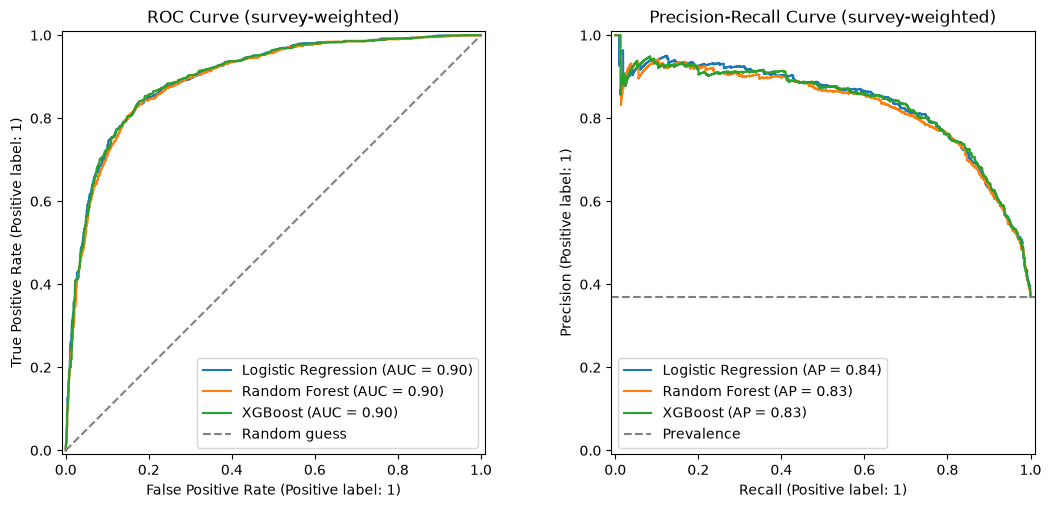

In [11]:
os.makedirs("../outputs/figures", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for name in model_specs:
    RocCurveDisplay.from_predictions(
        y_test, raw_probs[name], sample_weight=w_test, name=name, ax=axes[0]
    )
    PrecisionRecallDisplay.from_predictions(
        y_test, raw_probs[name], sample_weight=w_test, name=name, ax=axes[1]
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
axes[0].set_title("ROC Curve (survey-weighted)")
axes[0].legend(loc="lower right")

prevalence = np.average(y_test, weights=w_test)
axes[1].axhline(prevalence, linestyle="--", color="gray", label="Prevalence")
axes[1].set_title("Precision-Recall Curve (survey-weighted)")
axes[1].legend(loc="lower left")

fig.savefig(
    "../outputs/figures/model_comparison_roc_pr.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Calibration Curves

Same weighted binning as `04` and `05`: predictions are grouped into 10
equal-width bins, and each bin's weighted mean prediction is plotted against its
weighted observed fragility rate.

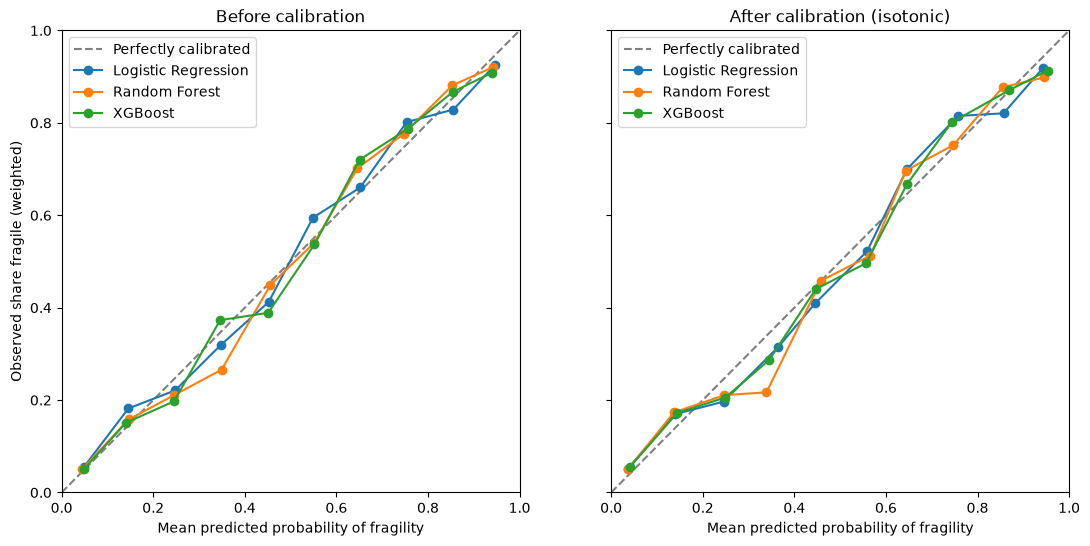

In [12]:
def weighted_calibration(y_true, prob, weights, n_bins=10):
    y_true, prob, weights = map(np.asarray, (y_true, prob, weights))
    edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.clip(np.digitize(prob, edges) - 1, 0, n_bins - 1)

    rows = []
    for b in range(n_bins):
        in_bin = bin_ids == b
        if in_bin.any():
            rows.append({
                "mean_predicted": np.average(prob[in_bin], weights=weights[in_bin]),
                "observed_rate": np.average(y_true[in_bin], weights=weights[in_bin]),
                "n": int(in_bin.sum())
            })
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)

for ax, probs, title in [
    (axes[0], raw_probs, "Before calibration"),
    (axes[1], calibrated_probs, "After calibration (isotonic)")
]:
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
    for name in model_specs:
        curve = weighted_calibration(y_test, probs[name], w_test)
        ax.plot(curve["mean_predicted"], curve["observed_rate"], marker="o", label=name)
    ax.set_xlabel("Mean predicted probability of fragility")
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend()

axes[0].set_ylabel("Observed share fragile (weighted)")

fig.savefig(
    "../outputs/figures/model_comparison_calibration.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Summary

Survey-weighted, held-out test set (2,587 respondents), same 12 features and split
for every model:

| Model | ROC AUC | PR AUC | Brier |
|---|---|---|---|
| Logistic Regression | 0.899 | 0.836 | 0.120 |
| Random Forest | 0.895 | 0.828 | 0.123 |
| XGBoost (tuned) | 0.900 | 0.834 | 0.120 |
| Majority-class baseline (from `04`) | 0.500 | 0.370 | 0.370 |

- **All three models perform almost identically** and all far exceed the
  baselines. The ROC and precision-recall curves lie on top of each other.
- **Random forest** was tuned with 5-fold weighted cross-validation (ranked by
  Brier): `max_depth=10`, `min_samples_leaf=5`, `max_features="sqrt"`, 300 trees.
  It finished slightly behind the other two.
- **Calibration was not needed.** All three models were already well calibrated,
  and isotonic calibration slightly *raised* each model's Brier score (by about
  0.001-0.002). The uncalibrated models are kept.
- **Why the models tie:** with 12 mostly categorical features there are few
  nonlinear patterns or interactions for tree models to exploit, so the extra
  flexibility of random forests and boosting does not help.
- **Recommendation:** use **logistic regression** as the primary model. It
  matches the best performance, and its coefficients are directly interpretable,
  which suits the project's goal of decision support a non-technical person can
  understand. XGBoost can serve as the comparison model for the SHAP analysis.

Next steps:
- Subgroup performance and calibration analysis (income, race/ethnicity, age,
  region)
- SHAP explanations, compared against the logistic-regression coefficients
- Re-check the ranking on the larger feature set from `03_preprocessing`, where
  tree models may gain an advantage